In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math
import copy
from skimage.metrics import structural_similarity as ssim, mean_squared_error as mse

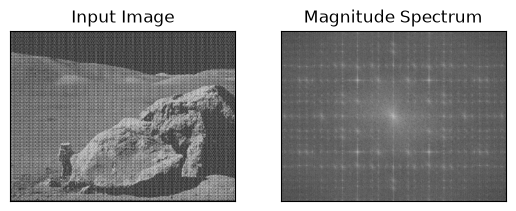

In [2]:
image = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(image),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

plt.subplot(121),plt.imshow(image, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

# Высокочастотная фильтрация на основе ядра Гаусса

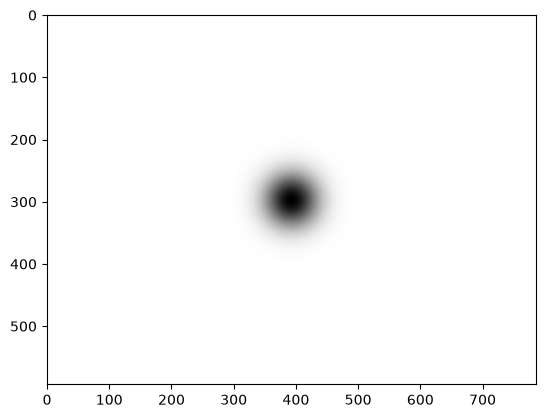

In [3]:
rows, cols = image.shape
crow, ccol = rows // 2, cols // 2

D0 = 30

u = np.arange(rows).reshape(-1, 1) - crow
v = np.arange(cols).reshape(1, -1) - ccol
D2 = u**2 + v**2

G_low = np.exp(-D2 / (2 * D0**2))
G_high = 1 - G_low

mask_high = np.zeros((rows, cols, 2), np.float32)
mask_high[:, :, 0] = G_high
mask_high[:, :, 1] = G_high

plt.imshow(mask_high[:,:,0], cmap='gray')
plt.show()

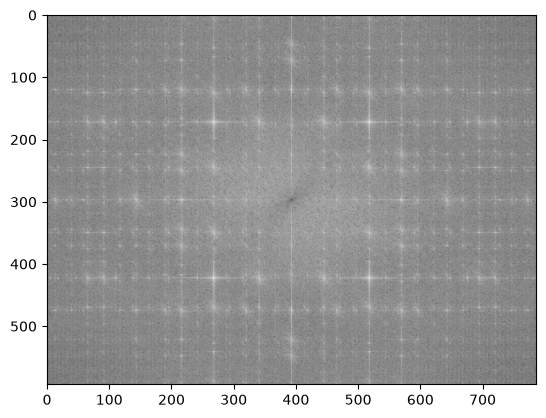

In [4]:
dft_shift_high = dft_shift * mask_high

filtering_magn_res = 20*np.log(cv.magnitude(dft_shift_high[:,:,0], dft_shift_high[:,:,1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')
plt.show()

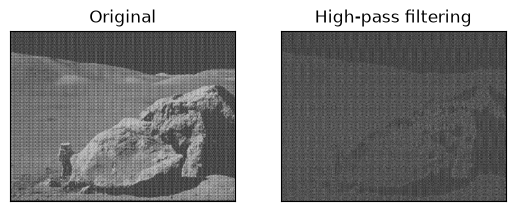

In [5]:
f_ishift = np.fft.ifftshift(dft_shift_high)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

plt.subplot(121),plt.imshow(image, cmap = 'gray')
plt.title('Original'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('High-pass filtering'), plt.xticks([]), plt.yticks([])
plt.show()

# Свертка Гаусса через Фурье

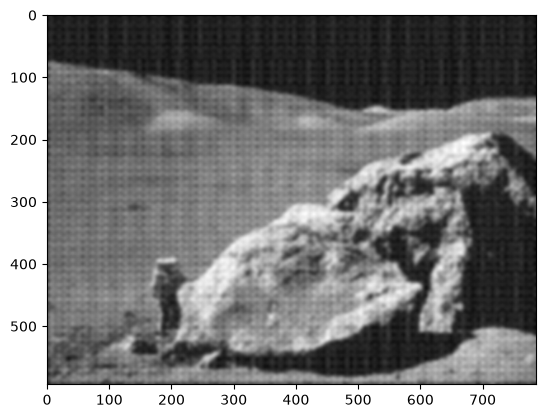

In [6]:
k_size = 15
k_1d = cv.getGaussianKernel(k_size, sigma=3)
k_2d = k_1d @ k_1d.T

conv_direct = cv.filter2D(image, -1, k_2d)

plt.imshow(conv_direct, cmap='gray')
plt.show()

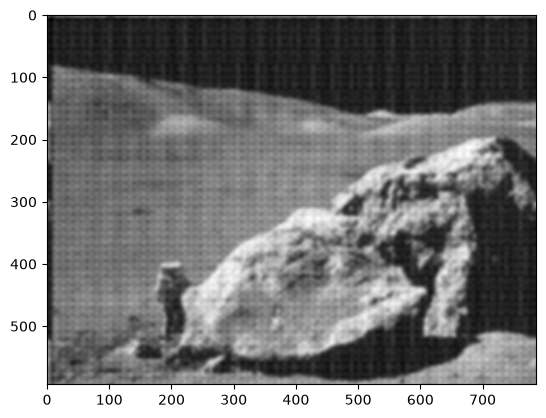

In [7]:
k_size = 15
k_1d = cv.getGaussianKernel(k_size, sigma=3)
k_2d = k_1d @ k_1d.T

image_f = np.float32(image)

k_padded = np.zeros(image.shape, np.float32)
k_padded[:k_size, :k_size] = k_2d

dft_img = cv.dft(image_f, flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(k_padded, flags=cv.DFT_COMPLEX_OUTPUT)

dft_product = cv.mulSpectrums(dft_img, dft_kernel, 0)

img_conv_fft = cv.idft(dft_product)
img_conv_fft = cv.magnitude(img_conv_fft[:,:,0], img_conv_fft[:,:,1])

img_conv_fft = img_conv_fft / (image.shape[0] * image.shape[1])

plt.imshow(img_conv_fft, cmap='gray')
plt.show()

# Удаление шума с помощью Фурье

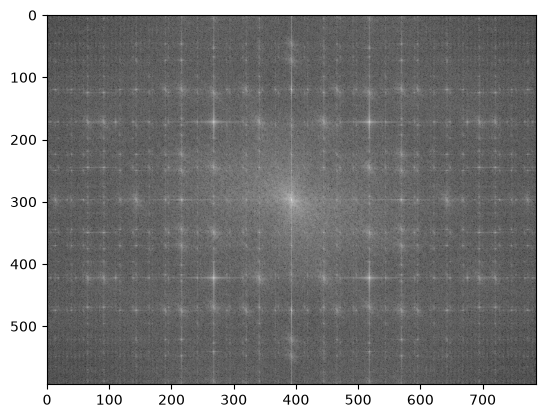

In [8]:
plt.imshow(magnitude_spectrum, cmap='gray')
plt.show()

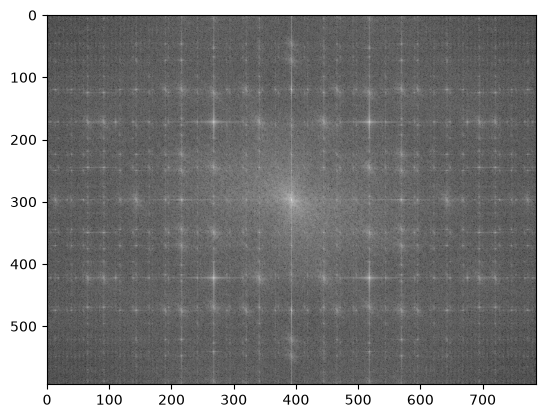

In [9]:
spectrum_uint8 = cv.normalize(magnitude_spectrum, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.imshow(spectrum_uint8, cmap='gray')
plt.show()

## Применение пороговой бинаризации

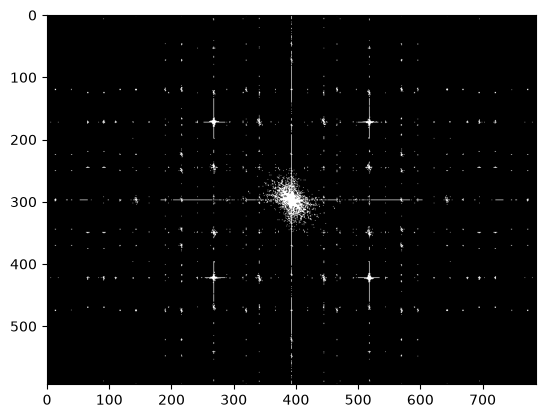

In [10]:
threshold_value = 140
ret, peaks_mask = cv.threshold(spectrum_uint8, threshold_value, 255, cv.THRESH_BINARY)

plt.imshow(peaks_mask, cmap='gray')
plt.show()

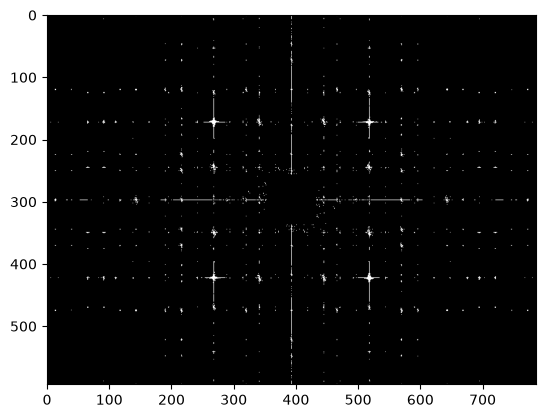

In [11]:
rows, cols = image.shape
crow, ccol = rows // 2, cols // 2
exclude_radius = 40

peaks_mask[crow-exclude_radius:crow+exclude_radius,
           ccol-exclude_radius:ccol+exclude_radius] = 0

plt.imshow(peaks_mask, cmap='gray')
plt.show()

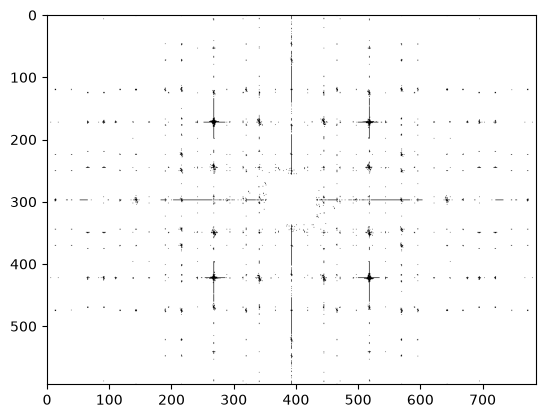

In [12]:
mask_noise = np.ones((rows, cols, 2), np.float32)
mask_noise[:, :, 0] = np.where(peaks_mask, 0, 1)
mask_noise[:, :, 1] = np.where(peaks_mask, 0, 1)

plt.imshow(mask_noise[:,:,0], cmap='gray')
plt.show()

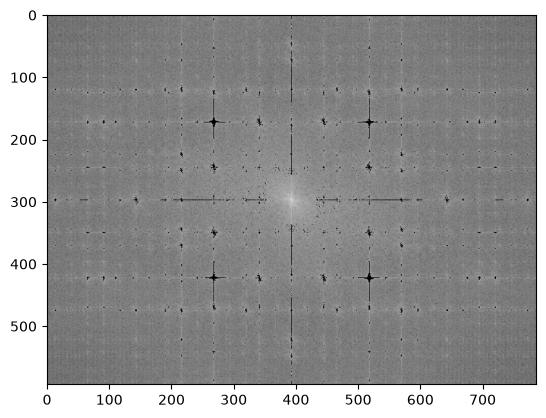

In [13]:
dft_shift_noise = dft_shift * mask_noise

filtering_magn_res = 20*np.log(cv.magnitude(dft_shift_noise[:,:,0],dft_shift_noise[:,:,1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')
plt.show()

f_ishift = np.fft.ifftshift(dft_shift_noise)
image_denoised = cv.idft(f_ishift)
image_denoised = cv.magnitude(image_denoised[:,:,0], image_denoised[:,:,1])

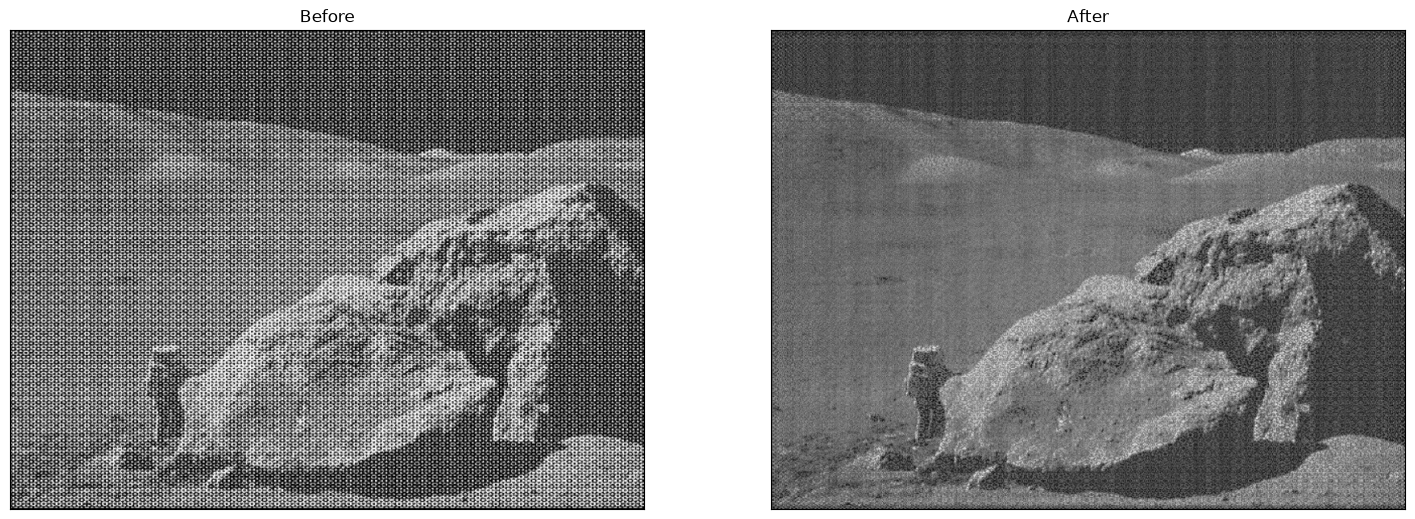

In [14]:
plt.figure(figsize=(18, 9))

plt.subplot(121)
plt.imshow(image, cmap='gray')
plt.title('Before'), plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(image_denoised, cmap='gray')
plt.title('Аfter'), plt.xticks([]), plt.yticks([])

plt.show()